Load Dataset


In [7]:
import pandas as pd

df = pd.read_csv(
    'train_FD001.txt',
    sep=' ',
    header=None
)

df.head()


,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,NaN,NaN
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,NaN,NaN
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,NaN,NaN
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,NaN,NaN
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,NaN,NaN


Assign Correct CMAPSS Column Names

In [8]:
# Assign CMAPSS column names
columns = [
    'unit', 'cycle',
    'op1', 'op2', 'op3',
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',
    'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10',
    'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
    'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',
    'sensor_21', 'sensor_22', 'sensor_23'
]

df.columns = columns

df.head()


,unit,cycle,op1,op2,op3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,sensor_22,sensor_23
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,NaN,NaN
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,NaN,NaN
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,NaN,NaN
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,NaN,NaN
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,NaN,NaN


Remove the Empty Sensor Columns

In [9]:
df = df.drop(columns=['sensor_22', 'sensor_23'])


Create Remaining Useful Life

In [10]:
# Compute RUL
max_cycle = df.groupby('unit')['cycle'].max()
df['RUL'] = df.apply(lambda row: max_cycle[row['unit']] - row['cycle'], axis=1)

df[['unit', 'cycle', 'RUL']].head()


,unit,cycle,RUL
0,1,1,191.0
1,1,2,190.0
2,1,3,189.0
3,1,4,188.0
4,1,5,187.0


Create Health Index

In [11]:
# Normalize RUL to create health index
df['health_index'] = df['RUL'] / df['RUL'].max()

df[['RUL', 'health_index']].head()


,RUL,health_index
0,191.0,0.529086
1,190.0,0.526316
2,189.0,0.523546
3,188.0,0.520776
4,187.0,0.518006


In [12]:
df[['cycle', 'sensor_2', 'sensor_3', 'sensor_4', 'health_index']].head()


,cycle,sensor_2,sensor_3,sensor_4,health_index
0,1,641.82,1589.70,1400.60,0.529086
1,2,642.15,1591.82,1403.14,0.526316
2,3,642.35,1587.99,1404.20,0.523546
3,4,642.35,1582.79,1401.87,0.520776
4,5,642.37,1582.85,1406.22,0.518006


Time-Based Train/Test Split (70% / 30%)

In [13]:
# Sort by time (cycle)
df_sorted = df.sort_values('cycle')

split_index = int(0.7 * len(df_sorted))

X_train = df_sorted[features].iloc[:split_index]
X_test  = df_sorted[features].iloc[split_index:]

y_train = df_sorted[target].iloc[:split_index]
y_test  = df_sorted[target].iloc[split_index:]

X_train.shape, X_test.shape


((14441, 4), (6190, 4))

Train Linear Regression Model

In [14]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)


Train Random Forest Regressor

In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)


Evaluate Models (MSE & R²)

In [16]:
from sklearn.metrics import mean_squared_error, r2_score

# Linear Regression
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Random Forest
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

mse_lr, r2_lr, mse_rf, r2_rf


(0.02748424597543378,
 -1.1974842653503948,
 0.005794873054789196,
 0.5366748511498413)

Plot: Predicted vs True Health Index (Linear Regression)

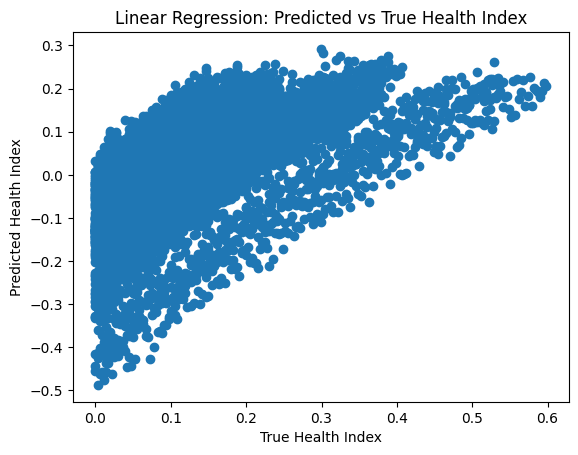

In [18]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_lr)
plt.xlabel('True Health Index')
plt.ylabel('Predicted Health Index')
plt.title('Linear Regression: Predicted vs True Health Index')
plt.show()


Plot: Predicted vs True Health Index (Random Forest)

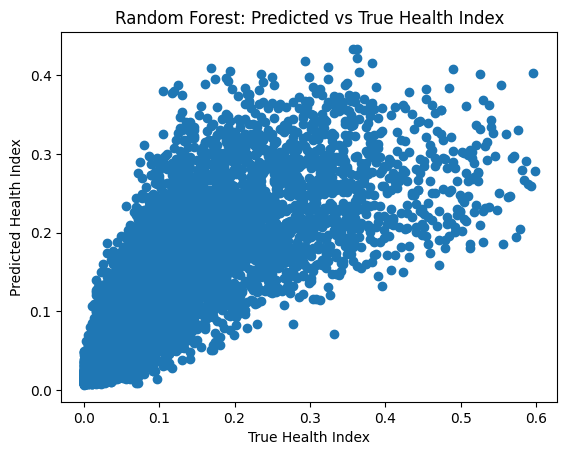

In [19]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_rf)
plt.xlabel('True Health Index')
plt.ylabel('Predicted Health Index')
plt.title('Random Forest: Predicted vs True Health Index')
plt.show()


Linear Regression performs poorly due to the non-linear degradation patterns present in CMAPSS sensor data, resulting in a negative R² score. In contrast, the Random Forest model significantly improves predictive performance by capturing complex sensor interactions, achieving a lower MSE and a positive R² of 0.54.